X shape: (1000, 2)
y shape: (1000,)
First 5 features (X):
 [[ 0.75424625  0.23148074]
 [-0.75615888  0.15325888]
 [-0.81539193  0.17328203]
 [-0.39373073  0.69288277]
 [ 0.44220765 -0.89672343]]
First 5 labels (y): [1 1 1 1 0]


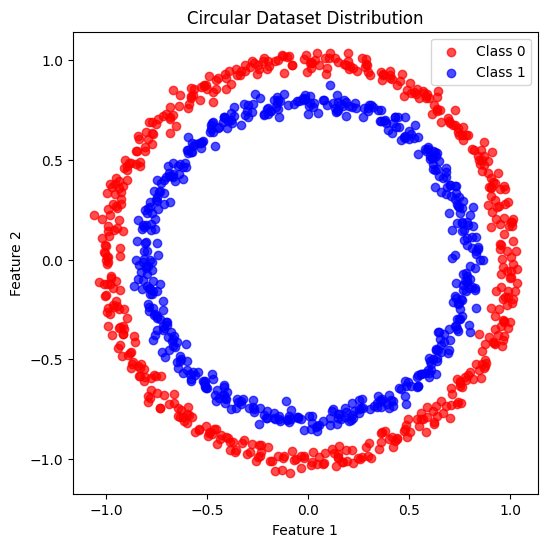

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



--- Training Basic Model ---
Basic Model Accuracy: 50.00%
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


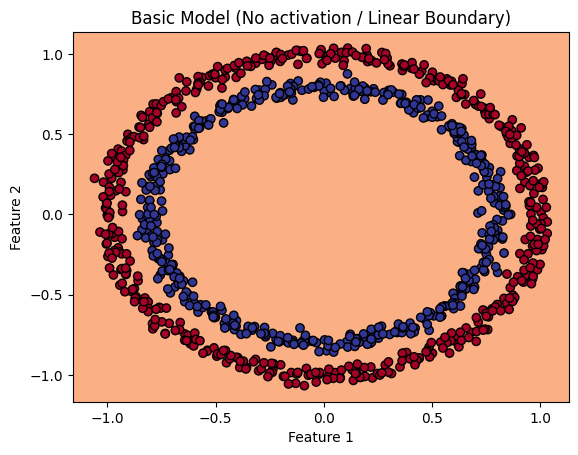


--- Training Improved Model on Train Set ---

Improved Model - Train Loss: 0.0001 | Train Accuracy: 100.00%
Improved Model - Test Loss: 0.0036 | Test Accuracy: 100.00%
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


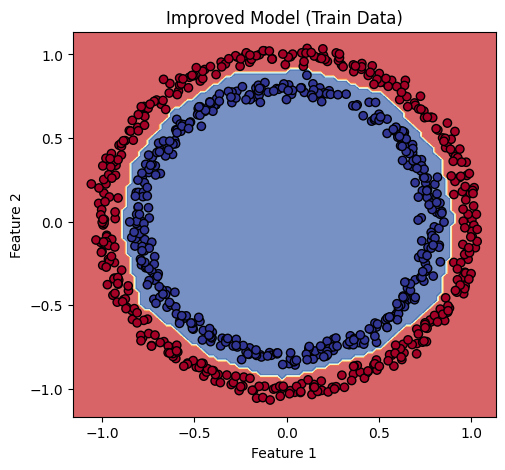

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


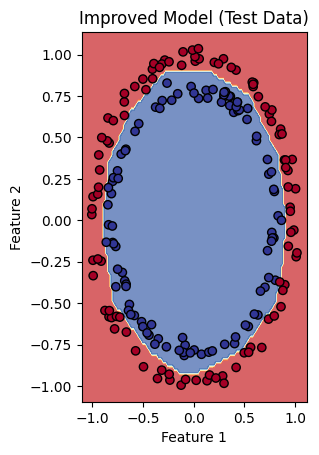

'\nKey Takeaways:\n1. Linear models (such as single dense layer with no non-linear activations) fail entirely on non-linearly separable datasets like circular datasets.\n2. Incorporating non-linear activation functions (like ReLU) in hidden layers enables neural networks to capture complex, non-linear geometric patterns.\n3. Utilizing modern optimizers (like Adam) and deeper hidden units greatly speeds up convergence and improves overall evaluation accuracy.\n4. Visualizing decision boundaries is highly effective for identifying whether a model is underfitting or overfitting the feature space.\n'

In [1]:
# ==========================================
# 1. Understanding Classification Types
# ==========================================
"""
- Binary Classification: Classifying instances into one of two distinct classes (e.g., Spam vs. Not Spam, Circle vs. No Circle).
- Multi-class Classification: Classifying instances into one of three or more mutually exclusive classes (e.g., classifying an image as either a cat, dog, or bird).
- Multi-label Classification: Assigning one or more labels to an instance (e.g., tagging a movie with multiple genres like Action, Comedy, and Sci-Fi simultaneously).
"""

# ==========================================
# 2. Set Up Python Environment and Dataset
# ==========================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split

# Generate dataset
samples = 1000
X, y = make_circles(samples, noise=0.03, random_state=42)

print('X shape:', X.shape)
print('y shape:', y.shape)
print('First 5 features (X):\n', X[:5])
print('First 5 labels (y):', y[:5])

# Visualize data distribution
plt.figure(figsize=(6, 6))
plt.scatter(X[y == 0, 0], X[y == 0, 1], color='red', label='Class 0', alpha=0.7)
plt.scatter(X[y == 1, 0], X[y == 1, 1], color='blue', label='Class 1', alpha=0.7)
plt.title("Circular Dataset Distribution")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()

# ==========================================
# 5. Define Decision Boundary Plot Function
# ==========================================
def plot_decision_boundary(model, X, y, title="Decision Boundary"):
    x_min, x_max = X[:, 0].min() - 0.1, X[:, 0].max() + 0.1
    y_min, y_max = X[:, 1].min() - 0.1, X[:, 1].max() + 0.1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100), np.linspace(y_min, y_max, 100))

    grid = np.c_[xx.ravel(), yy.ravel()]
    preds = model.predict(grid)

    if preds.shape[-1] > 1:
        # For multiclass
        preds = np.argmax(preds, axis=1)
    else:
        # For binary with sigmoid output
        preds = np.round(preds)

    preds = preds.reshape(xx.shape)

    plt.contourf(xx, yy, preds, cmap=plt.cm.RdYlBu, alpha=0.7)
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.RdYlBu, edgecolors='k')
    plt.title(title)
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.show()

# ==========================================
# 3. Build a Basic Neural Network Model
# ==========================================
tf.random.set_seed(42)

basic_model = tf.keras.Sequential([
    tf.keras.layers.Dense(1, input_shape=(2,))
])

basic_model.compile(
    loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
    optimizer=tf.keras.optimizers.SGD(),
    metrics=['accuracy']
)

print("\n--- Training Basic Model ---")
history_basic = basic_model.fit(X, y, epochs=100, verbose=0)

_, basic_accuracy = basic_model.evaluate(X, y, verbose=0)
print(f"Basic Model Accuracy: {basic_accuracy * 100:.2f}%")
plot_decision_boundary(basic_model, X, y, title="Basic Model (No activation / Linear Boundary)")

# ==========================================
# 4, 6, 7 & 8. Improved Model with Train/Test Split
# ==========================================
# Split the dataset: 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Build improved model using Hidden Layers, ReLU, and Sigmoid activations
improved_model = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='relu', input_shape=(2,)),
    tf.keras.layers.Dense(10, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

# Use Adam Optimizer and Binary Crossentropy
improved_model.compile(
    loss=tf.keras.losses.BinaryCrossentropy(),
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.01),
    metrics=['accuracy']
)

print("\n--- Training Improved Model on Train Set ---")
history_improved = improved_model.fit(X_train, y_train, epochs=200, verbose=0, validation_data=(X_test, y_test))

# Evaluate and compare performance
train_loss, train_acc = improved_model.evaluate(X_train, y_train, verbose=0)
test_loss, test_acc = improved_model.evaluate(X_test, y_test, verbose=0)

print(f"\nImproved Model - Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc*100:.2f}%")
print(f"Improved Model - Test Loss: {test_loss:.4f} | Test Accuracy: {test_acc*100:.2f}%")

# Visualize Decision Boundaries
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plot_decision_boundary(improved_model, X_train, y_train, title="Improved Model (Train Data)")
plt.subplot(1, 2, 2)
plot_decision_boundary(improved_model, X_test, y_test, title="Improved Model (Test Data)")

# ==========================================
# 9. Key Takeaways Summary
# ==========================================
"""
Key Takeaways:
1. Linear models (such as single dense layer with no non-linear activations) fail entirely on non-linearly separable datasets like circular datasets.
2. Incorporating non-linear activation functions (like ReLU) in hidden layers enables neural networks to capture complex, non-linear geometric patterns.
3. Utilizing modern optimizers (like Adam) and deeper hidden units greatly speeds up convergence and improves overall evaluation accuracy.
4. Visualizing decision boundaries is highly effective for identifying whether a model is underfitting or overfitting the feature space.
"""